# Final model comparison and error analysis

Compare logistic regression, random forest, XGBoost, LightGBM, and stacking under **70/15/15** and **LOOCV** evaluation. The first result table is the 70/15/15 test comparison; the second is LOOCV.

**Comparison specification:** use the fixed base-model hyperparameters, 75% feature selection, and preprocessing from `stacking.ipynb` for both standalone models and the stack. These are **not** the tuned standalone configurations in `feature_engineering.ipynb`. Matching specifications isolates the contribution of stacking and avoids carrying full-dataset-selected hyperparameters into LOOCV. No settings or thresholds are chosen from these evaluation results.

For the holdout experiment, fit on 70%, assess validation on 15% without changing settings, then refit every model on training + validation (85%) and evaluate the same 15% test rows. For LOOCV, each model predicts every row once from a fit that excludes it. Stacking adds three-fold internal out-of-fold training within each outer training set. Imputation, encoding, scaling and selection are fitted inside the relevant pipelines.

All experiments reuse an already explored dataset. Treat them as internal descriptive comparisons, not independent confirmation. The strategies have different training/evaluation sizes and their scores are not directly interchangeable. Code `1` is the positive class; clinical meanings of the codes are not assumed.

In [1]:
# If needed, uncomment and run once:
# %pip install numpy pandas matplotlib seaborn scipy scikit-learn xgboost lightgbm
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score, log_loss,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)
RANDOM_STATE = 42
TARGET = "gallstone_status"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import LeaveOneOut
from time import perf_counter
from sklearn.metrics import confusion_matrix

## Load data and define models

Use source row indices to align predictions. They are not patient identifiers. The row-level evaluation assumes independent observations; repeated patients would require grouped splitting.

In [2]:
candidates = [Path("dataset_gallstone"), Path("dataset_gallstone.xlsx"),
              Path("INFOSYS722/Iteration3_OpenStack/dataset_gallstone"),
              Path("INFOSYS722/Iteration3_OpenStack/dataset_gallstone.xlsx")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place the dataset beside this notebook or run from the projects directory.")
data = pd.read_excel(DATA_PATH) if DATA_PATH.suffix == ".xlsx" else pd.read_csv(DATA_PATH)
removed_index_cols = []
for c in list(data.columns):
    if str(c).startswith("Unnamed:") or not str(c).strip():
        values = pd.to_numeric(data[c], errors="coerce").to_numpy()
        if any(np.array_equal(values, np.arange(start, len(data) + start)) for start in [0, 1]):
            removed_index_cols.append(c)
data = data.drop(columns=removed_index_cols)
assert TARGET in data and data[TARGET].notna().all(), "Target must exist and have no missing values."
assert set(data[TARGET].unique()) == {0, 1}, "This notebook expects a binary target coded 0/1."
# A row-level split cannot protect against repeated patients without a patient identifier.
assert not data.duplicated().any(), "Review duplicate records before creating a row-level split."
X = data.drop(columns=TARGET).replace([np.inf, -np.inf], np.nan)
y = data[TARGET].astype(int)
print(f"Loaded {len(data)} rows and {X.shape[1]} raw predictors; removed index columns: {removed_index_cols}")
print("If patients have multiple records, replace the row split with patient-grouped splitting.")

Loaded 319 rows and 38 raw predictors; removed index columns: ['Unnamed: 0']
If patients have multiple records, replace the row split with patient-grouped splitting.


In [3]:
coded_fields = ["gender", "comorbidity", "cad", "hypothyroidism", "hyperlipidemia", "dm", "hfa"]
categorical_features = [c for c in X if c in coded_fields or not pd.api.types.is_numeric_dtype(X[c])]
numeric_features = [c for c in X if c not in categorical_features]
print("Numeric measurements:", numeric_features)
print("Categorical predictors:", categorical_features)
def make_preprocessor(scale_numeric=False):
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler() if scale_numeric else "passthrough"),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numeric", numeric, numeric_features),
        ("categorical", categorical, categorical_features),
    ], remainder="drop")
def make_pipeline(model, scale_numeric=False):
    return Pipeline([
        ("preprocess", make_preprocessor(scale_numeric)),
        ("select", SelectPercentile(score_func=f_classif, percentile=75)),
        ("model", model),
    ])

def make_stack():
    base_models = [
        ("logistic", make_pipeline(LogisticRegression(C=1.0, max_iter=3000,
                                                       random_state=RANDOM_STATE), True)),
        ("random_forest", make_pipeline(RandomForestClassifier(
            n_estimators=60, max_depth=5, min_samples_leaf=4,
            n_jobs=1, random_state=RANDOM_STATE))),
        ("xgboost", make_pipeline(XGBClassifier(
            n_estimators=60, learning_rate=0.05, max_depth=2, reg_lambda=1.0,
            subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
            tree_method="hist", n_jobs=1, random_state=RANDOM_STATE))),
        ("lightgbm", make_pipeline(LGBMClassifier(
            n_estimators=60, learning_rate=0.05, num_leaves=7, min_child_samples=20,
            colsample_bytree=0.8, deterministic=True, force_col_wise=True,
            verbosity=-1, n_jobs=1, random_state=RANDOM_STATE))),
    ]
    meta_model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(C=1.0, max_iter=3000, random_state=RANDOM_STATE)),
    ])
    return StackingClassifier(
        estimators=base_models, final_estimator=meta_model,
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        stack_method="predict_proba", passthrough=False, n_jobs=1)

stack_template = make_stack()
print("Base models:", [name for name, _ in stack_template.estimators])
print("Feature roles come from fixed schema/dtypes; no full-data outcome ranking is used.")
model_names = ["Logistic regression", "Random forest", "XGBoost", "LightGBM", "Stacking"]
model_templates = {name: clone(estimator) for name, (_, estimator)
                   in zip(model_names[:-1], make_stack().estimators)}
model_templates["Stacking"] = make_stack()
THRESHOLD = 0.5

Numeric measurements: ['age', 'height', 'weight', 'bmi', 'tbw', 'ecw', 'icw', 'ecf_tbw', 'tbfr_pct', 'lm_pct', 'protein_pct', 'vfr', 'bm', 'mm', 'obesity_pct', 'tfc', 'vfa', 'vma_kg', 'glucose', 'tc', 'ldl', 'hdl', 'triglyceride', 'ast', 'alt', 'alp', 'creatinine', 'gfr', 'crp', 'hgb', 'vitamin_d']
Categorical predictors: ['gender', 'comorbidity', 'cad', 'hypothyroidism', 'hyperlipidemia', 'dm', 'hfa']
Base models: ['logistic', 'random_forest', 'xgboost', 'lightgbm']
Feature roles come from fixed schema/dtypes; no full-data outcome ranking is used.


In [4]:
def evaluate_probabilities(target, probabilities):
    prediction = (probabilities >= 0.5).astype(int)
    return {"roc_auc": roc_auc_score(target, probabilities),
            "average_precision": average_precision_score(target, probabilities),
            "accuracy": accuracy_score(target, prediction),
            "balanced_accuracy": balanced_accuracy_score(target, prediction),
            "precision": precision_score(target, prediction, zero_division=0),
            "recall": recall_score(target, prediction, zero_division=0),
            "f1": f1_score(target, prediction, zero_division=0),
            "log_loss": log_loss(target, probabilities, labels=[0, 1])}


def summary_row(name, target, probabilities, seconds):
    tn, fp, fn, tp = confusion_matrix(target, probabilities >= THRESHOLD, labels=[0, 1]).ravel()
    return {"Model": name, "N": len(target), **evaluate_probabilities(target, probabilities),
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "fit_predict_seconds": seconds}
def prediction_rows(strategy, name, features, target, probabilities):
    prediction = (probabilities >= THRESHOLD).astype(int)
    actual = np.asarray(target)
    return pd.DataFrame({"strategy": strategy, "model": name, "source_row": features.index,
                         "actual": actual, "probability_1": probabilities, "prediction": prediction,
                         "error": prediction != actual,
                         "error_type": np.select([(actual == 0) & (prediction == 1),
                                                   (actual == 1) & (prediction == 0)],
                                                  ["FP", "FN"], default="Correct"),
                         "wrong_class_probability": np.where(actual == 0, probabilities, 1-probabilities)})
report_columns = ["Model", "N", "roc_auc", "average_precision", "accuracy", "balanced_accuracy",
                  "precision", "recall", "specificity", "f1", "log_loss", "TN", "FP", "FN", "TP",
                  "fit_predict_seconds"]

In [5]:
X_train, X_reserved, y_train, y_reserved = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_reserved, y_reserved, test_size=0.50, stratify=y_reserved, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_valid) + len(X_test) == len(X)
split_summary = pd.DataFrame([
    {"split": name, "rows": len(target), "fraction": len(target) / len(y),
     "class_0": int((target == 0).sum()), "class_1": int((target == 1).sum())}
    for name, target in [("train", y_train), ("validation", y_valid), ("test", y_test)]
])
print("Split counts:", dict(zip(split_summary["split"], split_summary["rows"])))
# Preserve row membership for reproducibility; these are source row indices, not patient IDs.
split_membership = pd.concat([
    pd.Series(name, index=frame.index, name="split")
    for name, frame in [("train", X_train), ("validation", X_valid), ("test", X_test)]
]).sort_index().rename_axis("source_row")

Split counts: {'train': 223, 'validation': 48, 'test': 48}


## 1. Final table — 70/15/15 test

All models are evaluated on the same 48 test observations after development refitting. The fixed settings remain unchanged after validation. ROC-AUC/AP use probabilities; classification metrics and error counts use threshold 0.5. Runtime includes both the training/validation fit and the development/test refit. Table order is fixed, not a model-selection decision.

In [6]:
X_development = pd.concat([X_train, X_valid])
y_development = pd.concat([y_train, y_valid])
holdout_rows, validation_rows, prediction_frames = [], [], []
holdout_models = {}
for name, template in model_templates.items():
    start = perf_counter()
    training_model = clone(template).fit(X_train, y_train)
    valid_probability = training_model.predict_proba(X_valid)[:, 1]
    validation_rows.append(summary_row(name, y_valid, valid_probability, perf_counter() - start))
    fitted_model = clone(template).fit(X_development, y_development)
    probability = fitted_model.predict_proba(X_test)[:, 1]
    holdout_models[name] = fitted_model
    holdout_rows.append(summary_row(name, y_test, probability, perf_counter() - start))
    prediction_frames.append(prediction_rows("70/15/15 test", name, X_test, y_test, probability))
holdout_results = pd.DataFrame(holdout_rows)[report_columns]
validation_results = pd.DataFrame(validation_rows)[report_columns]
display(holdout_results.round(3))

,Model,N,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,specificity,f1,log_loss,TN,FP,FN,TP,fit_predict_seconds
0,Logistic regression,48,0.884,0.905,0.875,0.875,0.846,0.917,0.833,0.880,0.446,20,4,2,22,0.023
1,Random forest,48,0.929,0.917,0.833,0.833,0.833,0.833,0.833,0.833,0.445,20,4,4,20,0.063
2,XGBoost,48,0.905,0.905,0.792,0.792,0.769,0.833,0.750,0.800,0.449,18,6,4,20,0.032
3,LightGBM,48,0.889,0.901,0.792,0.792,0.792,0.792,0.792,0.792,0.435,19,5,5,19,0.030
4,Stacking,48,0.920,0.930,0.833,0.833,0.833,0.833,0.833,0.833,0.381,20,4,4,20,0.445


## 2. Final table — LOOCV

Run 319 outer folds for every model. Every prediction excludes its row from all fitted preprocessing and model stages. Aggregate probabilities across rows before calculating ROC-AUC; a one-observation fold cannot supply its own ROC-AUC. Runtime covers all 319 fits and predictions per model; it is not a per-prediction latency measurement.

In [7]:
loo_rows = []
loo_probabilities = {name: np.full(len(y), np.nan) for name in model_names}
loo_seconds = {name: 0.0 for name in model_names}
seen = np.zeros(len(y), dtype=int)
for fold, (train_positions, test_positions) in enumerate(LeaveOneOut().split(X, y), start=1):
    assert not np.intersect1d(train_positions, test_positions).size
    for name, template in model_templates.items():
        start = perf_counter()
        fitted_model = clone(template).fit(X.iloc[train_positions], y.iloc[train_positions])
        loo_probabilities[name][test_positions] = fitted_model.predict_proba(X.iloc[test_positions])[:, 1]
        loo_seconds[name] += perf_counter() - start
    seen[test_positions] += 1
    if fold == 1 or fold % 40 == 0 or fold == len(y):
        print(f"LOOCV {fold}/{len(y)} complete for all five models", flush=True)
assert np.all(seen == 1)
for name in model_names:
    probability = loo_probabilities[name]
    assert np.isfinite(probability).all() and np.all((probability >= 0) & (probability <= 1))
    loo_rows.append(summary_row(name, y, probability, loo_seconds[name]))
    prediction_frames.append(prediction_rows("LOOCV", name, X, y, probability))
loocv_results = pd.DataFrame(loo_rows)[report_columns]
display(loocv_results.round(3))
predictions = pd.concat(prediction_frames, ignore_index=True)

LOOCV 1/319 complete for all five models
LOOCV 40/319 complete for all five models
LOOCV 80/319 complete for all five models
LOOCV 120/319 complete for all five models
LOOCV 160/319 complete for all five models
LOOCV 200/319 complete for all five models
LOOCV 240/319 complete for all five models
LOOCV 280/319 complete for all five models
LOOCV 319/319 complete for all five models


,Model,N,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,specificity,f1,log_loss,TN,FP,FN,TP,fit_predict_seconds
0,Logistic regression,319,0.863,0.857,0.784,0.783,0.807,0.741,0.826,0.772,0.537,133,28,41,117,2.458
1,Random forest,319,0.852,0.870,0.781,0.780,0.789,0.759,0.801,0.774,0.507,129,32,38,120,10.764
2,XGBoost,319,0.837,0.859,0.768,0.768,0.780,0.741,0.795,0.760,0.499,128,33,41,117,3.925
3,LightGBM,319,0.844,0.867,0.781,0.780,0.782,0.772,0.789,0.777,0.484,127,34,36,122,3.490
4,Stacking,319,0.875,0.886,0.781,0.780,0.793,0.753,0.807,0.773,0.441,130,31,39,119,78.233


## 3. Error types and discrimination plots

**FP:** actual code 0, predicted code 1. **FN:** actual code 1, predicted code 0. Compare specificity for code-0 errors and recall for code-1 errors. Raw error counts are only comparable within each strategy because the test sizes differ.

ROC and precision–recall plots compare probability ranking; the confusion matrices show decisions at the fixed threshold. These plots are descriptive and do not establish statistically significant superiority.

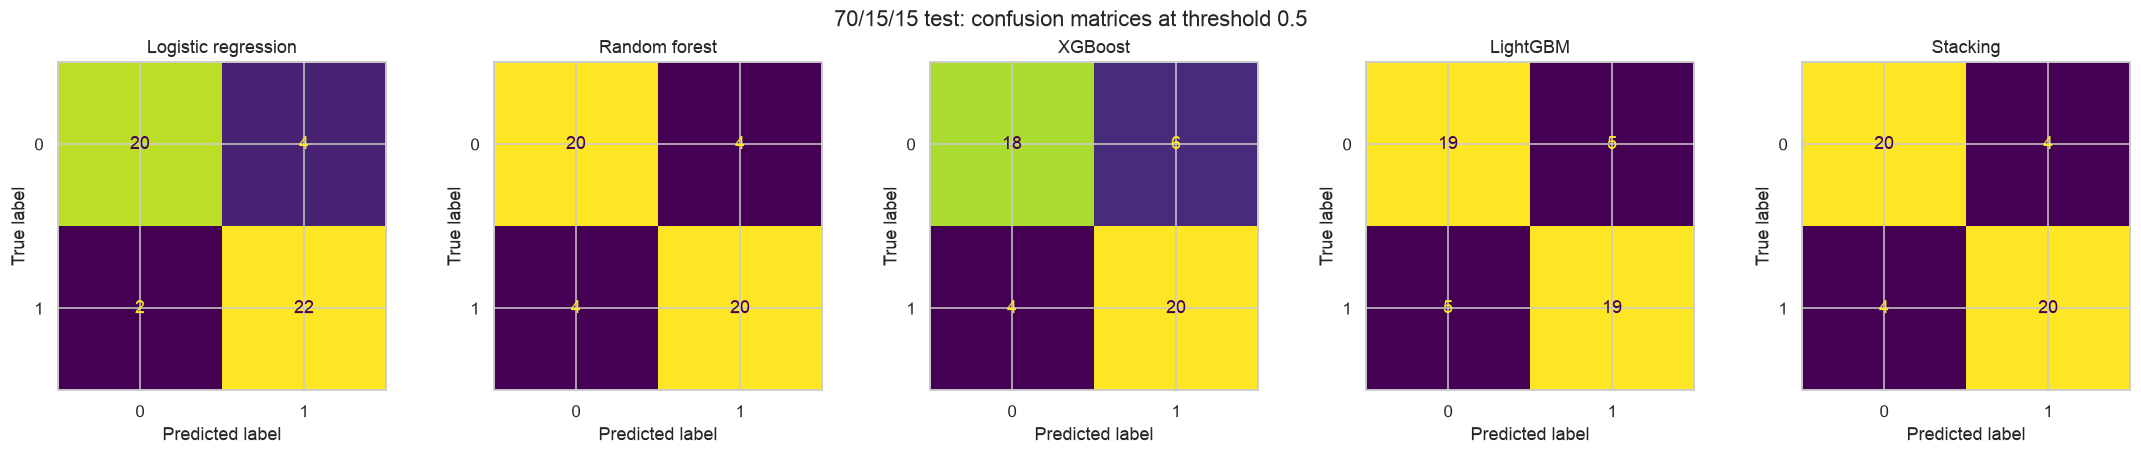

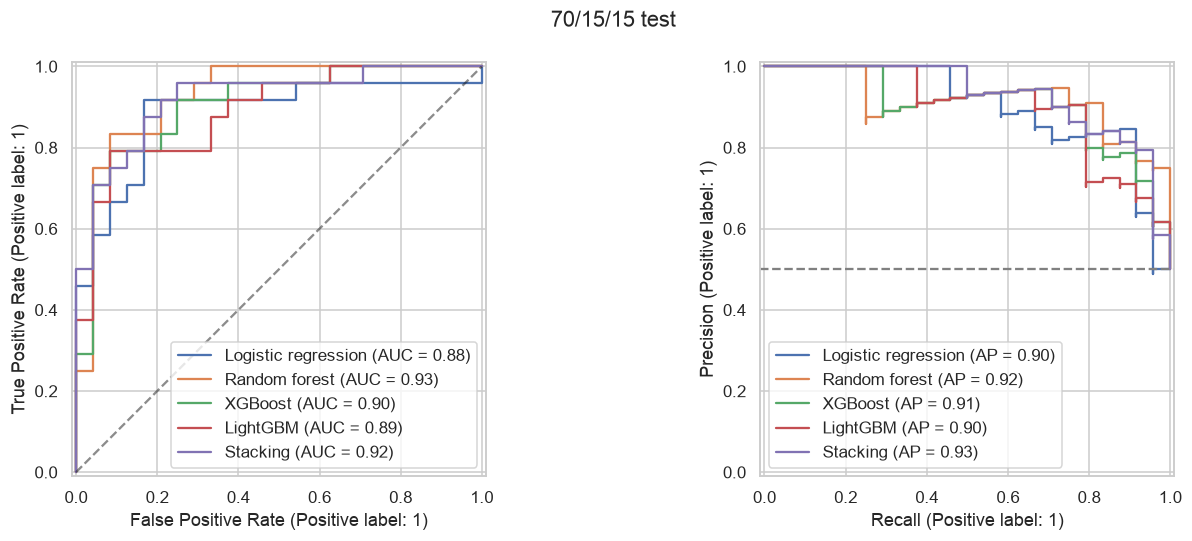

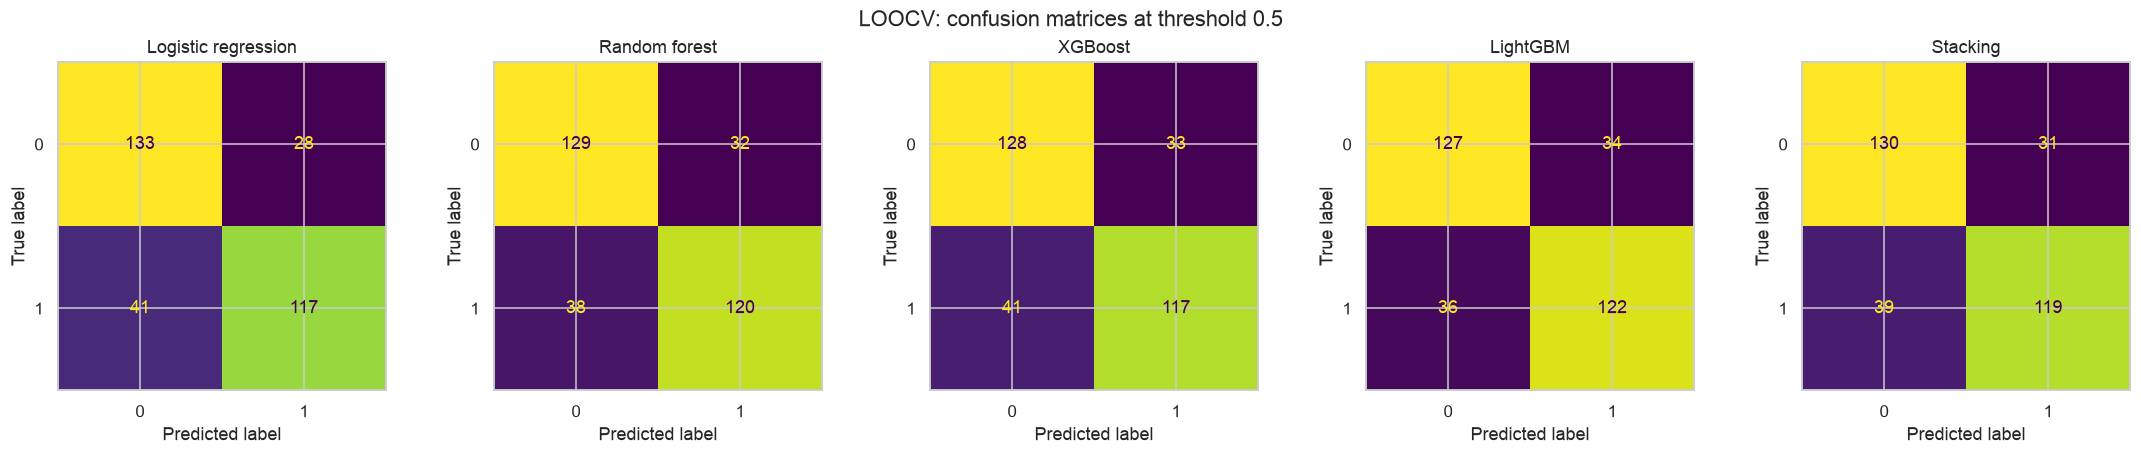

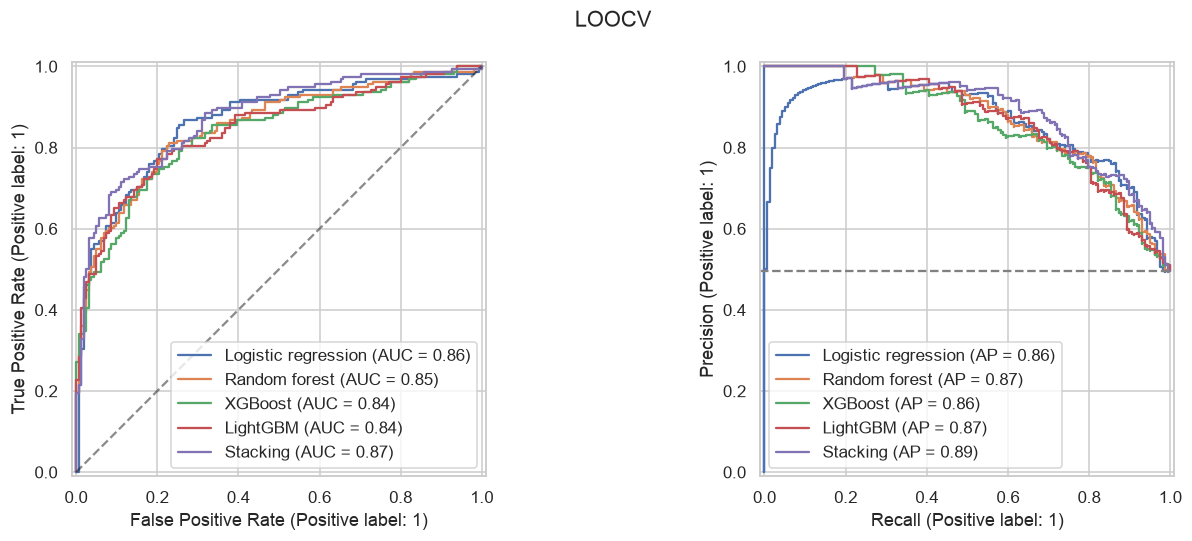

In [8]:
for strategy in ["70/15/15 test", "LOOCV"]:
    subset = predictions.loc[predictions.strategy == strategy]
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, name in zip(axes, model_names):
        rows = subset.loc[subset.model == name]
        ConfusionMatrixDisplay.from_predictions(rows.actual, rows.prediction, labels=[0, 1],
                                                 ax=ax, colorbar=False)
        ax.set_title(name)
    fig.suptitle(f"{strategy}: confusion matrices at threshold {THRESHOLD}")
    plt.tight_layout(); plt.show()
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for name in model_names:
        rows = subset.loc[subset.model == name]
        RocCurveDisplay.from_predictions(rows.actual, rows.probability_1, name=name, ax=axes[0])
        PrecisionRecallDisplay.from_predictions(rows.actual, rows.probability_1, name=name, ax=axes[1])
    axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[1].axhline(rows.actual.mean(), color="grey", linestyle="--")
    fig.suptitle(strategy)
    plt.tight_layout(); plt.show()

## 4. Shared errors and confident mistakes

Count how many of the five models misclassify each observation. The overlap matrix counts observations that **both** models get wrong; its diagonal is each model's error count. A row's number of failing models is not five independent pieces of evidence, because the models share inputs and stacking contains these base models.

The case-review tables show the most widely misclassified rows and the largest probabilities assigned to the wrong class. Review measurements and source records rather than deleting difficult cases. Future changes motivated by these errors require a new evaluation.

70/15/15 test: 3 rows wrong for all five models; 33 correct for all five.
Ten most confident incorrect model predictions:
LOOCV: 32 rows wrong for all five models; 207 correct for all five.
Ten most confident incorrect model predictions:


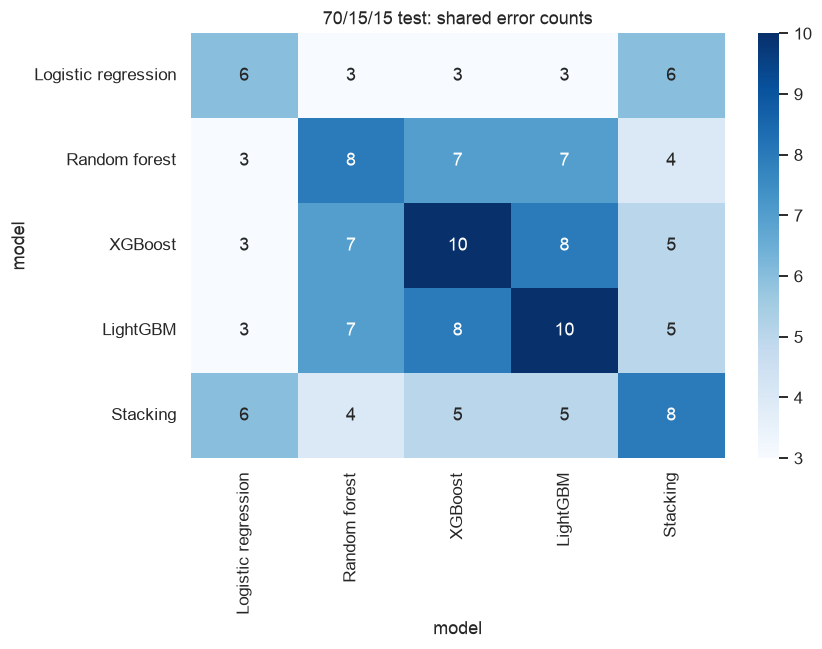

,strategy,actual,models_wrong,mean_probability_1,wrong_models,age,gender,bmi,glucose,crp
source_row,,,,,,,,,,
309,70/15/15 test,1,5,0.237065,"Logistic regression, Random forest, XGBoost, L...",57,0,36.5,98.0,0.00
141,70/15/15 test,0,5,0.831716,"Logistic regression, Random forest, XGBoost, L...",55,1,37.3,117.0,2.51
116,70/15/15 test,0,5,0.654845,"Logistic regression, Random forest, XGBoost, L...",56,1,25.3,99.0,0.18
297,70/15/15 test,1,4,0.454646,"Random forest, XGBoost, LightGBM, Stacking",46,1,34.6,91.0,0.00
199,70/15/15 test,1,3,0.497074,"Random forest, XGBoost, LightGBM",35,0,37.2,91.0,0.00
91,70/15/15 test,0,3,0.485848,"Random forest, XGBoost, LightGBM",35,1,29.5,91.0,0.00
300,70/15/15 test,1,3,0.450768,"XGBoost, LightGBM, Stacking",66,1,25.3,105.0,0.00
294,70/15/15 test,1,2,0.495880,"Random forest, LightGBM",59,0,25.3,218.0,0.80
83,70/15/15 test,0,2,0.458417,"XGBoost, LightGBM",56,1,40.3,129.0,1.36


,source_row,model,actual,prediction,probability_1,error_type
45,278,Logistic regression,1,0,0.003331,FN
214,141,Stacking,0,1,0.894365,FP
166,141,LightGBM,0,1,0.876396,FP
196,309,Stacking,1,0,0.133160,FN
118,141,XGBoost,0,1,0.818949,FP
4,309,Logistic regression,1,0,0.190319,FN
22,141,Logistic regression,0,1,0.804287,FP
148,309,LightGBM,1,0,0.222595,FN
209,116,Stacking,0,1,0.765755,FP
70,141,Random forest,0,1,0.764585,FP


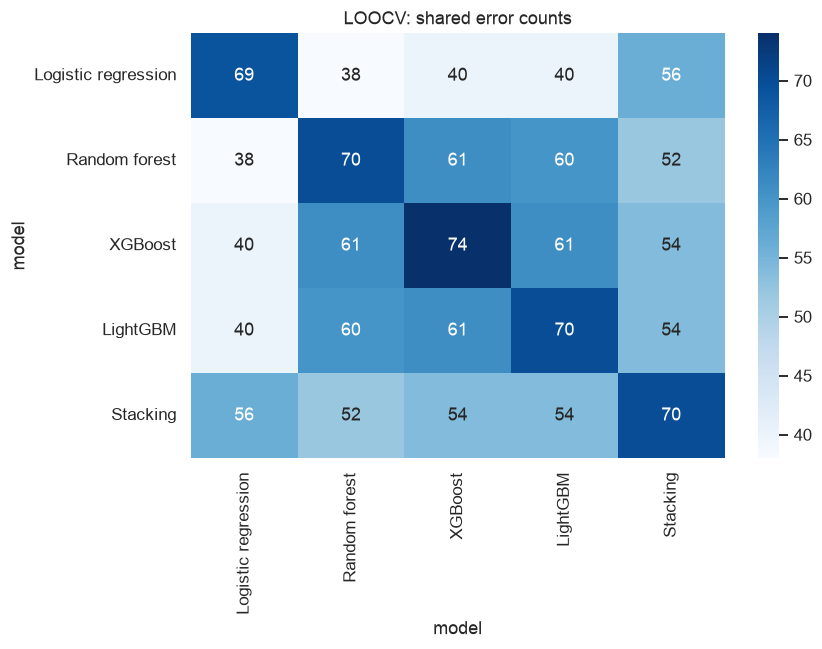

,strategy,actual,models_wrong,mean_probability_1,wrong_models,age,gender,bmi,glucose,crp
source_row,,,,,,,,,,
192,LOOCV,1,5,0.199306,"Logistic regression, Random forest, XGBoost, L...",59,0,29.1,115.0,0.04
207,LOOCV,1,5,0.284181,"Logistic regression, Random forest, XGBoost, L...",35,1,30.2,98.0,0.00
215,LOOCV,1,5,0.202293,"Logistic regression, Random forest, XGBoost, L...",31,0,24.9,97.0,0.00
153,LOOCV,0,5,0.852985,"Logistic regression, Random forest, XGBoost, L...",26,1,31.1,105.0,31.00
299,LOOCV,1,5,0.131902,"Logistic regression, Random forest, XGBoost, L...",59,0,26.6,101.0,0.20
66,LOOCV,0,5,0.676032,"Logistic regression, Random forest, XGBoost, L...",34,0,37.0,104.0,0.52
141,LOOCV,0,5,0.836059,"Logistic regression, Random forest, XGBoost, L...",55,1,37.3,117.0,2.51
119,LOOCV,0,5,0.641283,"Logistic regression, Random forest, XGBoost, L...",59,1,35.3,101.0,0.00
117,LOOCV,0,5,0.594123,"Logistic regression, Random forest, XGBoost, L...",47,1,27.7,83.0,0.31


,source_row,model,actual,prediction,probability_1,error_type
393,153,Logistic regression,0,1,1.000000,FP
518,278,Logistic regression,1,0,0.006848,FN
445,205,Logistic regression,1,0,0.008778,FN
557,317,Logistic regression,1,0,0.014828,FN
396,156,Logistic regression,0,1,0.958878,FP
539,299,Logistic regression,1,0,0.049467,FN
1833,317,Stacking,1,0,0.059064,FN
1672,156,Stacking,0,1,0.940629,FP
1669,153,Stacking,0,1,0.937624,FP
397,157,Logistic regression,0,1,0.931503,FP


In [9]:
case_tables = []
review_features = [c for c in ["age", "gender", "bmi", "glucose", "crp"] if c in X]
for strategy in ["70/15/15 test", "LOOCV"]:
    subset = predictions.loc[predictions.strategy == strategy]
    error_matrix = subset.pivot(index="source_row", columns="model", values="error").reindex(columns=model_names).astype(int)
    overlap = error_matrix.T @ error_matrix
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(overlap, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(f"{strategy}: shared error counts")
    plt.tight_layout(); plt.show()
    cases = subset.groupby("source_row").agg(actual=("actual", "first"),
        models_wrong=("error", "sum"), mean_probability_1=("probability_1", "mean"))
    failed_names = subset.loc[subset.error].groupby("source_row")["model"].agg(", ".join)
    cases["wrong_models"] = failed_names.reindex(cases.index).fillna("")
    cases = cases.join(X[review_features]).sort_values("models_wrong", ascending=False)
    cases.insert(0, "strategy", strategy)
    case_tables.append(cases.reset_index())
    print(f"{strategy}: {(cases.models_wrong == 5).sum()} rows wrong for all five models; "
          f"{(cases.models_wrong == 0).sum()} correct for all five.")
    display(cases.loc[cases.models_wrong > 0].head(15))
    print("Ten most confident incorrect model predictions:")
    display(subset.loc[subset.error].sort_values("wrong_class_probability", ascending=False)
            [["source_row", "model", "actual", "prediction", "probability_1", "error_type"]].head(10))
case_review = pd.concat(case_tables, ignore_index=True)

## 5. Exploratory subgroup error rates

Report counts and error rates by the original gender code, including each group's target composition and FP/FN denominators. Small subgroup rates are unstable. This is a descriptive audit, not evidence of fairness or clinical suitability; category meanings are undocumented.

In [10]:
subgroup_rows = []
if "gender" in X:
    grouped_predictions = predictions.merge(X[["gender"]], left_on="source_row", right_index=True, validate="many_to_one")
    for (strategy, name, group), rows in grouped_predictions.groupby(["strategy", "model", "gender"], dropna=False):
        n0, n1 = int((rows.actual == 0).sum()), int((rows.actual == 1).sum())
        fp, fn = int((rows.error_type == "FP").sum()), int((rows.error_type == "FN").sum())
        subgroup_rows.append({"strategy": strategy, "model": name, "gender_code": group,
            "N": len(rows), "class_0": n0, "class_1": n1, "errors": int(rows.error.sum()),
            "error_rate": rows.error.mean(), "FP": fp, "FN": fn,
            "false_positive_rate": fp / n0 if n0 else np.nan,
            "false_negative_rate": fn / n1 if n1 else np.nan})
subgroup_results = pd.DataFrame(subgroup_rows)
display(subgroup_results.round(3))

,strategy,model,gender_code,N,class_0,class_1,errors,error_rate,FP,FN,false_positive_rate,false_negative_rate
0,70/15/15 test,LightGBM,0,21,13,8,3,0.143,0,3,0.000,0.375
1,70/15/15 test,LightGBM,1,27,11,16,7,0.259,5,2,0.455,0.125
2,70/15/15 test,Logistic regression,0,21,13,8,4,0.190,2,2,0.154,0.250
3,70/15/15 test,Logistic regression,1,27,11,16,2,0.074,2,0,0.182,0.000
4,70/15/15 test,Random forest,0,21,13,8,3,0.143,0,3,0.000,0.375
5,70/15/15 test,Random forest,1,27,11,16,5,0.185,4,1,0.364,0.062
6,70/15/15 test,Stacking,0,21,13,8,4,0.190,2,2,0.154,0.250
7,70/15/15 test,Stacking,1,27,11,16,4,0.148,2,2,0.182,0.125
8,70/15/15 test,XGBoost,0,21,13,8,3,0.143,1,2,0.077,0.250
9,70/15/15 test,XGBoost,1,27,11,16,7,0.259,5,2,0.455,0.125


## 6. Save comparison tables and error-analysis outputs

The two final CSV tables preserve full numeric precision. `final_comparison.md` provides compact report-ready tables. Validation metrics are saved separately as supporting diagnostics. All prediction rows include their evaluation strategy and original source row for traceability.

In [11]:
RESULTS_DIR = DATA_PATH.parent / "error_analysis_results"
RESULTS_DIR.mkdir(exist_ok=True)
holdout_results.to_csv(RESULTS_DIR / "01_holdout_test_results.csv", index=False)
loocv_results.to_csv(RESULTS_DIR / "02_loocv_results.csv", index=False)
validation_results.to_csv(RESULTS_DIR / "validation_results.csv", index=False)
predictions.to_csv(RESULTS_DIR / "all_predictions.csv", index=False)
case_review.to_csv(RESULTS_DIR / "case_review.csv", index=False)
subgroup_results.to_csv(RESULTS_DIR / "subgroup_errors.csv", index=False)
split_membership.to_csv(RESULTS_DIR / "split_membership.csv")
def markdown_table(table):
    columns = ["Model", "roc_auc", "accuracy", "precision", "recall", "f1", "FP", "FN"]
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    for _, row in table.iterrows():
        lines.append("| " + " | ".join(str(row[c]) if c in ["Model", "FP", "FN"] else f"{row[c]:.3f}" for c in columns) + " |")
    return "\n".join(lines)
report = ("# Final comparison: fixed model settings from stacking.ipynb\n\n"
          "These are internal reused-data comparisons, not the earlier tuned standalone configurations. "
          "Threshold = 0.5; preprocessing/selection refitted inside each evaluation fold.\n\n"
          "## 1. 70/15/15 test — 48 rows; refitted on 271 development rows\n\n" + markdown_table(holdout_results) +
          "\n\n## 2. LOOCV — 319 held-out predictions per model\n\n" + markdown_table(loocv_results) + "\n")
(RESULTS_DIR / "final_comparison.md").write_text(report)
print("Saved results to", RESULTS_DIR.resolve())

Saved results to /Users/quyduong106/projects/INFOSYS722/Iteration3_OpenStack/error_analysis_results


## 7. Repeated 70/15/15 evaluation — five random split seeds

Repeat the same fixed-model experiment across **five distinct, reproducibly generated split seeds**, selected without examining scores. Every model uses the same partition for a given seed: 223 training, 48 validation, and 48 test rows. For each split, fit on training, evaluate validation without changing settings, then refit on training + validation and evaluate test.

Only the **data-split seed varies**. Keep model randomness and the stack's inner CV seed at 42 to focus this experiment on sensitivity to partitioning. Every fit starts from a fresh clone, so imputation, scaling, encoding, feature selection and stacking are refitted.

Report **mean ± sample standard deviation** (`ddof=1`) across the five test evaluations. Also save **sample variance** (`ddof=1`) as a separate numeric column; variance is in squared metric units and is not the usual quantity shown after ±. These are measures of split-to-split variability, **not confidence intervals**. Repeated test sets may overlap, so the five evaluations are not independent samples. Do not select the best seed or retune from these results.

The earlier single-seed tables remain available above for traceability. The updated report's first table summarises the five test splits; LOOCV is unchanged.

In [12]:
SEED_GENERATOR = 2026
SPLIT_SEEDS = np.random.default_rng(SEED_GENERATOR).choice(100_000, size=5, replace=False).tolist()
print("Five split seeds:", SPLIT_SEEDS)
repeat_rows, repeat_validation_rows, repeat_predictions, repeat_membership = [], [], [], []
for split_seed in SPLIT_SEEDS:
    X_tr, X_res, y_tr, y_res = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=split_seed)
    X_va, X_te, y_va, y_te = train_test_split(
        X_res, y_res, test_size=0.50, stratify=y_res, random_state=split_seed)
    assert set(X_tr.index).isdisjoint(X_va.index)
    assert set(X_tr.index).isdisjoint(X_te.index)
    assert set(X_va.index).isdisjoint(X_te.index)
    assert len(X_tr) + len(X_va) + len(X_te) == len(X)
    for split_name, frame in [("train", X_tr), ("validation", X_va), ("test", X_te)]:
        repeat_membership.append(pd.DataFrame({"seed": split_seed, "source_row": frame.index,
                                               "split": split_name}))
    X_dev, y_dev = pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va])
    for name, template in model_templates.items():
        started = perf_counter()
        training_fit = clone(template).fit(X_tr, y_tr)
        va_probability = training_fit.predict_proba(X_va)[:, 1]
        repeat_validation_rows.append({"seed": split_seed,
            **summary_row(name, y_va, va_probability, perf_counter() - started)})
        development_fit = clone(template).fit(X_dev, y_dev)
        te_probability = development_fit.predict_proba(X_te)[:, 1]
        repeat_rows.append({"seed": split_seed,
            **summary_row(name, y_te, te_probability, perf_counter() - started)})
        repeat_predictions.append(prediction_rows("Repeated 70/15/15 test", name, X_te, y_te,
                                                  te_probability).assign(seed=split_seed))
    print(f"Seed {split_seed}: {len(X_tr)}/{len(X_va)}/{len(X_te)} rows; all five models completed.", flush=True)
repeated_test_results = pd.DataFrame(repeat_rows)
repeated_validation_results = pd.DataFrame(repeat_validation_rows)
repeated_test_predictions = pd.concat(repeat_predictions, ignore_index=True)
repeated_split_membership = pd.concat(repeat_membership, ignore_index=True)
assert len(repeated_test_results) == 25
assert not repeated_test_predictions.duplicated(["seed", "model", "source_row"]).any()

Five split seeds: [63990, 36547, 17892, 85181, 2641]
Seed 63990: 223/48/48 rows; all five models completed.
Seed 36547: 223/48/48 rows; all five models completed.
/Users/quyduong106/projects/.gallstone-venv/lib/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/Users/quyduong106/projects/.gallstone-venv/lib/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/Users/quyduong106/projects/.gallstone-venv/lib/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/Users/quyduong106/projects/.gallstone-venv/lib/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:111: Runtime

Final repeated 70/15/15 test results: mean ± sample standard deviation (five seeds)
Individual seed test results:


,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,specificity,f1,log_loss,TN,FP,FN,TP,fit_predict_seconds
Model,,,,,,,,,,,,,,
Logistic regression,0.853 ± 0.054,0.861 ± 0.067,0.783 ± 0.050,0.783 ± 0.050,0.794 ± 0.056,0.767 ± 0.063,0.800 ± 0.062,0.779 ± 0.053,0.506 ± 0.069,19.200 ± 1.483,4.800 ± 1.483,5.600 ± 1.517,18.400 ± 1.517,0.018 ± 0.003
Random forest,0.873 ± 0.055,0.888 ± 0.052,0.804 ± 0.052,0.804 ± 0.052,0.815 ± 0.069,0.792 ± 0.042,0.817 ± 0.081,0.802 ± 0.048,0.504 ± 0.040,19.600 ± 1.949,4.400 ± 1.949,5.000 ± 1.000,19.000 ± 1.000,0.063 ± 0.000
XGBoost,0.874 ± 0.058,0.899 ± 0.047,0.808 ± 0.040,0.808 ± 0.040,0.857 ± 0.080,0.750 ± 0.042,0.867 ± 0.095,0.797 ± 0.033,0.475 ± 0.058,20.800 ± 2.280,3.200 ± 2.280,6.000 ± 1.000,18.000 ± 1.000,0.026 ± 0.003
LightGBM,0.860 ± 0.050,0.890 ± 0.043,0.792 ± 0.039,0.792 ± 0.039,0.816 ± 0.061,0.758 ± 0.054,0.825 ± 0.068,0.784 ± 0.039,0.471 ± 0.059,19.800 ± 1.643,4.200 ± 1.643,5.800 ± 1.304,18.200 ± 1.304,0.024 ± 0.004
Stacking,0.891 ± 0.053,0.904 ± 0.050,0.800 ± 0.032,0.800 ± 0.032,0.813 ± 0.051,0.783 ± 0.035,0.817 ± 0.063,0.797 ± 0.028,0.426 ± 0.085,19.600 ± 1.517,4.400 ± 1.517,5.200 ± 0.837,18.800 ± 0.837,0.445 ± 0.001


,seed,Model,roc_auc,accuracy,precision,recall,f1,FP,FN
0,63990,Logistic regression,0.844,0.812,0.800,0.833,0.816,5,4
1,63990,Random forest,0.818,0.750,0.731,0.792,0.760,7,5
2,63990,XGBoost,0.806,0.750,0.731,0.792,0.760,7,5
3,63990,LightGBM,0.811,0.750,0.750,0.750,0.750,6,6
4,63990,Stacking,0.837,0.792,0.769,0.833,0.800,6,4
5,36547,Logistic regression,0.814,0.729,0.762,0.667,0.711,5,8
6,36547,Random forest,0.880,0.854,0.870,0.833,0.851,3,4
7,36547,XGBoost,0.868,0.812,0.857,0.750,0.800,3,6
8,36547,LightGBM,0.856,0.833,0.864,0.792,0.826,3,5
9,36547,Stacking,0.901,0.812,0.857,0.750,0.800,3,6


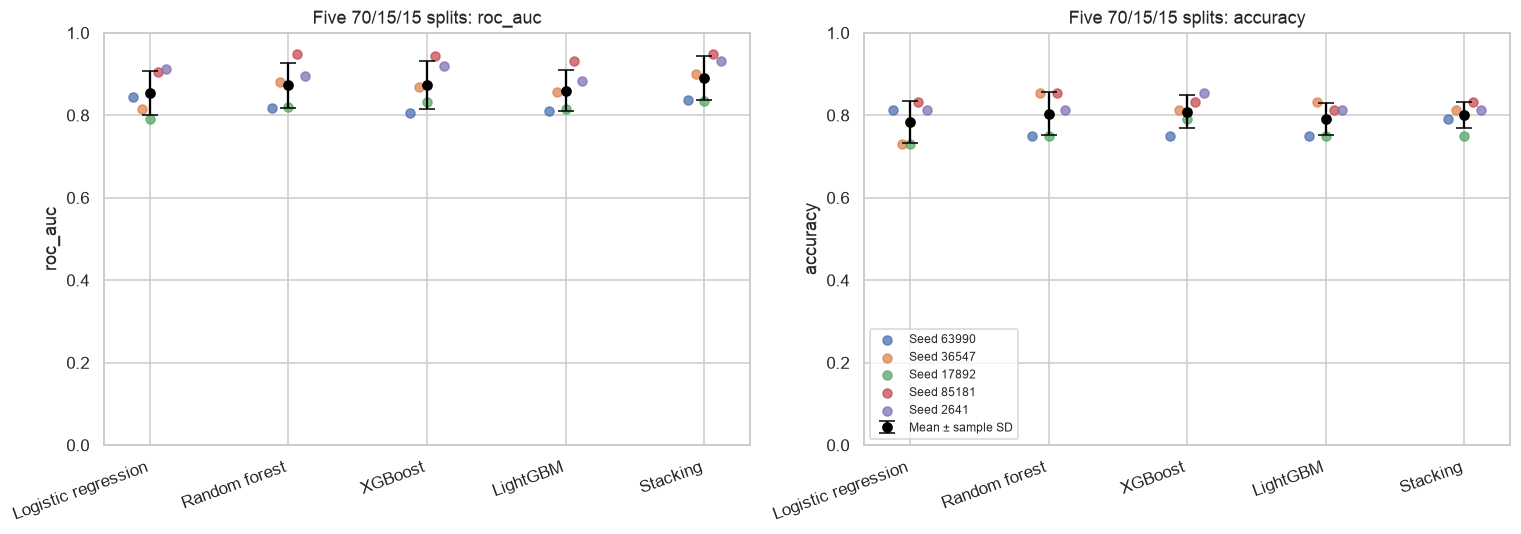

In [13]:
repeat_metrics = ["roc_auc", "average_precision", "accuracy", "balanced_accuracy", "precision",
                  "recall", "specificity", "f1", "log_loss", "TN", "FP", "FN", "TP", "fit_predict_seconds"]
summary_records = []
for name in model_names:
    runs = repeated_test_results.loc[repeated_test_results.Model == name]
    assert runs.seed.nunique() == 5
    for metric in repeat_metrics:
        summary_records.append({"Model": name, "metric": metric, "n_seeds": len(runs),
                                "mean": runs[metric].mean(), "std": runs[metric].std(ddof=1),
                                "variance": runs[metric].var(ddof=1)})
repeated_summary = pd.DataFrame(summary_records)
summary_display = pd.DataFrame(index=pd.Index(model_names, name="Model"))
for metric in repeat_metrics:
    stat = repeated_summary.loc[repeated_summary.metric == metric].set_index("Model").reindex(model_names)
    summary_display[metric] = [f"{mean:.3f} ± {sd:.3f}" for mean, sd in zip(stat["mean"], stat["std"])]
print("Final repeated 70/15/15 test results: mean ± sample standard deviation (five seeds)")
display(summary_display)
print("Individual seed test results:")
display(repeated_test_results[["seed", "Model", "roc_auc", "accuracy", "precision", "recall", "f1", "FP", "FN"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ["roc_auc", "accuracy"]):
    stat = repeated_summary.loc[repeated_summary.metric == metric].set_index("Model").reindex(model_names)
    positions = np.arange(len(model_names))
    ax.errorbar(positions, stat["mean"], yerr=stat["std"], fmt="o", capsize=5,
                color="black", label="Mean ± sample SD", zorder=5)
    for offset, seed in zip(np.linspace(-0.12, 0.12, len(SPLIT_SEEDS)), SPLIT_SEEDS):
        values = repeated_test_results.loc[repeated_test_results.seed == seed].set_index("Model").reindex(model_names)
        ax.scatter(positions + offset, values[metric], s=35, alpha=0.75, label=f"Seed {seed}")
    ax.set_xticks(positions, model_names, rotation=20, ha="right")
    ax.set(ylim=(0, 1), ylabel=metric, title=f"Five 70/15/15 splits: {metric}")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

In [14]:
REPEAT_RESULTS_DIR = DATA_PATH.parent / "error_analysis_results"
REPEAT_RESULTS_DIR.mkdir(exist_ok=True)
repeated_test_results.to_csv(REPEAT_RESULTS_DIR / "repeated_holdout_test_per_seed.csv", index=False)
repeated_validation_results.to_csv(REPEAT_RESULTS_DIR / "repeated_holdout_validation_per_seed.csv", index=False)
repeated_summary.to_csv(REPEAT_RESULTS_DIR / "repeated_holdout_summary.csv", index=False)
summary_display.to_csv(REPEAT_RESULTS_DIR / "repeated_holdout_mean_sd.csv")
repeated_test_predictions.to_csv(REPEAT_RESULTS_DIR / "repeated_holdout_test_predictions.csv", index=False)
repeated_split_membership.to_csv(REPEAT_RESULTS_DIR / "repeated_holdout_split_membership.csv", index=False)
report_metrics = ["roc_auc", "accuracy", "precision", "recall", "f1", "FP", "FN"]
def repeated_markdown_table():
    lines = ["| Model | " + " | ".join(report_metrics) + " |",
             "| " + " | ".join(["---"] * (len(report_metrics) + 1)) + " |"]
    for name in model_names:
        lines.append("| " + name + " | " + " | ".join(summary_display.loc[name, report_metrics]) + " |")
    return "\n".join(lines)
repeat_report = ("# Final model comparison\n\n"
    "Fixed settings from stacking.ipynb; positive class = 1; threshold = 0.5. "
    "Model/inner-CV randomness stays at 42; only split seeds vary.\n\n"
    "## 1. 70/15/15 test — five splits, mean ± sample standard deviation\n\n"
    f"Seeds: {SPLIT_SEEDS}. Each split: 223 training / 48 validation / 48 test, "
    "with final refit on 271 development rows. Sample variance is saved separately. "
    "These overlapping splits measure variability, not an independent confidence interval.\n\n"
    + repeated_markdown_table() + "\n")
(REPEAT_RESULTS_DIR / "repeated_holdout_summary.md").write_text(repeat_report)
# The existing LOOCV estimates are unchanged; preserve their report section.
report_path = REPEAT_RESULTS_DIR / "final_comparison.md"
if report_path.exists():
    previous_report = report_path.read_text()
    marker = "## 2. LOOCV"
    if marker in previous_report:
        repeat_report += "\n" + marker + previous_report.split(marker, 1)[1]
report_path.write_text(repeat_report)
print("Saved five-seed statistics, predictions, split membership and updated final report to", REPEAT_RESULTS_DIR.resolve())

Saved five-seed statistics, predictions, split membership and updated final report to /Users/quyduong106/projects/INFOSYS722/Iteration3_OpenStack/error_analysis_results
